In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.metrics import mean_absolute_error   
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate,StratifiedKFold,GridSearchCV
from sklearn.model_selection import GridSearchCV
from scipy.stats import uniform, randint
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier


In [2]:
wine = pd.read_csv('data/wine.csv')
wine.head(2)

data = wine[wine.columns[:-1]].values
label = wine['class'].values

train_data,test_data,train_label,test_label = \
train_test_split(data,label,test_size=0.2,random_state=42)

In [3]:
# RandomForestClassifier : 정규화 작업을 안 해도 됨 
rf = RandomForestClassifier(n_jobs=-1, random_state=42) 
scores = cross_validate(rf, train_data, train_label, return_train_score=True,n_jobs=-1)
# return_train_score=True 가 없을 경우 test 에 있는 score 점수만 출력 
print(scores['train_score'])
print(scores,['test_score'])

print(np.mean(scores['train_score']))
print(np.mean(scores['test_score']))


[0.9971133  0.99663219 0.9978355  0.9973545  0.9978355 ]
{'fit_time': array([0.30947399, 0.35845137, 0.28605461, 0.33783817, 0.33537555]), 'score_time': array([0.08042264, 0.04021287, 0.07603335, 0.04725528, 0.04324722]), 'test_score': array([0.88461538, 0.88942308, 0.90279115, 0.88931665, 0.88642926]), 'train_score': array([0.9971133 , 0.99663219, 0.9978355 , 0.9973545 , 0.9978355 ])} ['test_score']
0.9973541965122431
0.8905151032797809


In [4]:
rf.fit(train_data, train_label)
# print(rf.feature_importances_)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [5]:
wine.columns

Index(['alcohol', 'sugar', 'pH', 'class'], dtype='str')

In [6]:
print(rf.feature_importances_) # 라벨 데이터에 가장 영향을 미치는 데이터가 뭔지 알수 있음


[0.23167441 0.50039841 0.26792718]


In [7]:
rf = RandomForestClassifier(oob_score=True, n_jobs=-1, random_state=42)
rf.fit(train_data,train_label)
print(rf.oob_score_)

0.8934000384837406


In [8]:
# train_data,test_data,train_label,test_label = \
# train_test_split(data,label,test_size=0.2,random_state=42)

In [9]:
params = {
    'max_depth': range(5, 20, 1),
    'min_impurity_decrease': np.arange(0.0001, 0.001, 0.0001),
    'min_samples_split': range(2, 100, 10),
}

# n_jobs=-1 로 지정하면 모든 cpu core를 사용해서 처리하라는 의미
gs = GridSearchCV(DecisionTreeClassifier(random_state=42),params,n_jobs=-1, return_train_score=True)
gs.fit(train_data, train_label)


# 가장 좋은 모델들만 뽑아달라는 의미 
dt = gs.best_estimator_
print('train정확도 :', dt.score(train_data,train_label))
print('test정확도 :', dt.score(test_data,test_label))
print("가장 좋은 파라미터 :", gs.best_estimator_)
print(gs.cv_results_['mean_test_score'])

# dt = DecisionTreeClassifier(max_dept3,random_state=42)
# dt.fit(train_data,train_label)h=


train정확도 : 0.892053107562055
test정확도 : 0.8615384615384616
가장 좋은 파라미터 : DecisionTreeClassifier(max_depth=14, min_impurity_decrease=np.float64(0.0004),
                       min_samples_split=12, random_state=42)
[0.85780355 0.85799604 0.85799604 ... 0.86126601 0.86165063 0.86357629]


In [10]:
len(gs.cv_results_['mean_test_score'])

1350

In [11]:
alist = list(range(1,6))
alist

[1, 2, 3, 4, 5]

In [12]:
alist = list(range(1,1351))


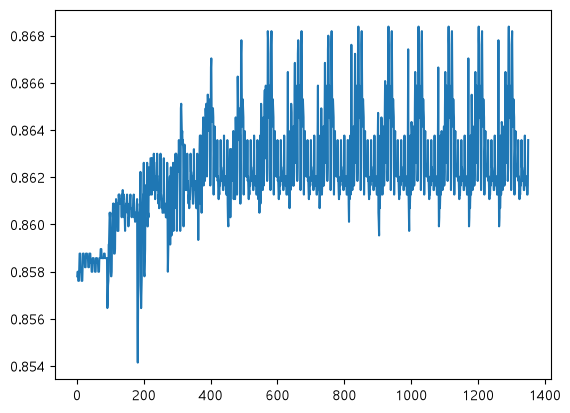

In [13]:
plt.plot(alist,gs.cv_results_['mean_test_score'])

plt.show()